In [1]:
import osgeo
import rasterio
import rasterio.plot
import rioxarray
import xarray
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from rasterio.windows import Window
from matplotlib import pyplot
import numpy as np
import matplotlib.patches as mpatches

In [2]:
path_LC_Hansen = 'C:/Users/minttu/Documents/LC_300m_data/ESACCI-LC-L4-LCCS-Map-300m-P1Y-2000-Resample_0.05deg.tif'

In [3]:
path_tree_cover = 'C:/Users/minttu/Documents/Tree_cover/TCD2010_0.05deg.tif'

In [4]:
Tree_cover = rioxarray.open_rasterio(path_tree_cover)

Nature article: 14 biomes defined by Nature conservancy:

Tropical moist
Tropical dry
Temperate broadleaf
Temperate coniferous
Boreal
Tropical grasslands
Temperate grasslands
Flooded grasslands
Montane grasslands
Tundra
Mediterranean forest
Deserts
Mangroves

In [5]:
LCHansen2000 = rioxarray.open_rasterio(path_LC_Hansen)

Tree cover, broadleaved, evergreen, closed to open (>15%) 50
Tree cover, needle leaved, evergreen, closed to open (>15%) 70
Tree cover, needle leaved, evergreen, closed (>40%) 71
Tree cover, needle leaved, evergreen, open (15 – 40%) 72

In [ ]:
LCHansen2000boreal = (LCHansen2000 == 70) | (LCHansen2000 == 71) | (LCHansen2000 == 72)

divide boreal into classes (latitude, altitude), sharper histograms, broadleaf, evergreen

Sparse vegetation (tree, shrub, herbaceous cover) (<15%) 150


In [8]:
LCHansen2000desert = (LCHansen2000 == 150)

Shrub or herbaceous cover, flooded, fresh/saline/brackish
water 180

In [9]:
LCHansen2000flooded_grassland = (LCHansen2000 == 180)

In [10]:
LCHansen2000boreal

<xarray.DataArray (band: 1, y: 3600, x: 7200)> Size: 26MB
array([[[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]]],
      shape=(1, 3600, 7200))
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 29kB 89.97 89.92 89.88 ... -89.88 -89.93 -89.98
  * x            (x) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [11]:
Tree_cover

<xarray.DataArray (band: 1, y: 3600, x: 7200)> Size: 104MB
[25920000 values with dtype=float32]
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 29kB 89.97 89.92 89.88 ... -89.88 -89.93 -89.98
  * x            (x) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

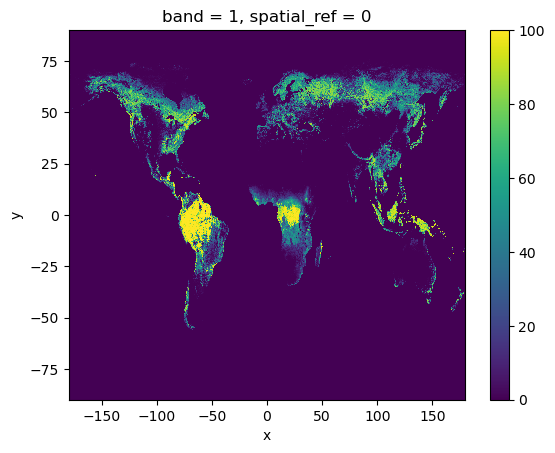

In [16]:
Tree_cover.plot()

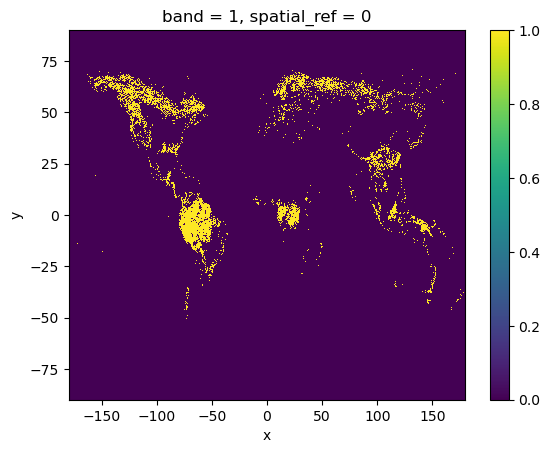

In [17]:
LCHansen2000boreal.plot()

In [12]:
borealTree_density = Tree_cover*LCHansen2000boreal

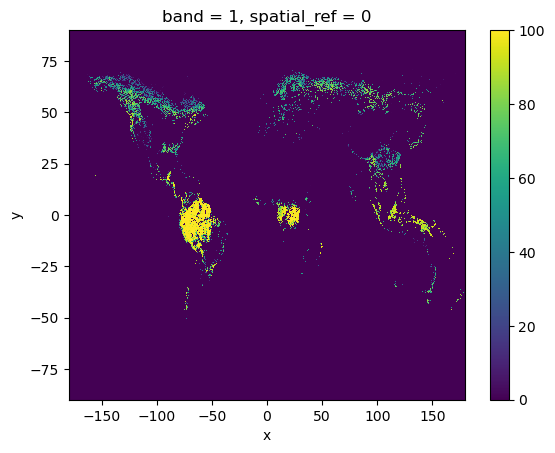

In [21]:
borealTree_density.plot()

In [13]:
borealTree_density

<xarray.DataArray (band: 1, y: 3600, x: 7200)> Size: 104MB
array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]],
      shape=(1, 3600, 7200), dtype=float32)
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 29kB 89.97 89.92 89.88 ... -89.88 -89.93 -89.98
  * x            (x) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [14]:
desertTree_density = Tree_cover*LCHansen2000desert

In [15]:
flooded_grassland_density = Tree_cover*LCHansen2000flooded_grassland

In [16]:
borealTree_densitycleaned = borealTree_density.where(borealTree_density != 0)

In [17]:
flooded_grassland_densitycleaned = flooded_grassland_density.where(flooded_grassland_density != 0)

Text(0.5, 1.0, 'LC Hansen Boreal forest density')

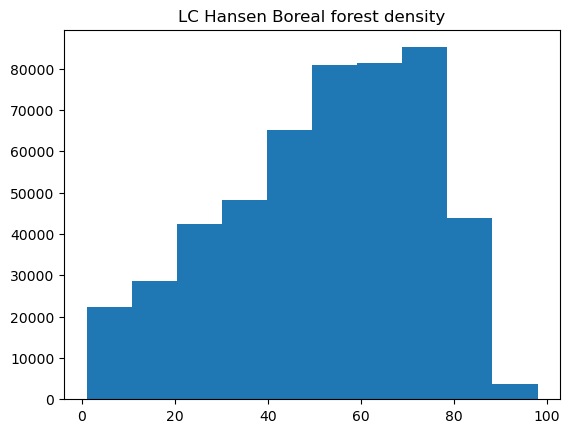

In [18]:
xarray.plot.hist(borealTree_densitycleaned)
pyplot.title("LC Hansen Boreal forest density")

In [36]:
desertTree_densitycleaned = desertTree_density.where(desertTree_density != 0)

Text(0.5, 1.0, 'LC Hansen Desert forest density')

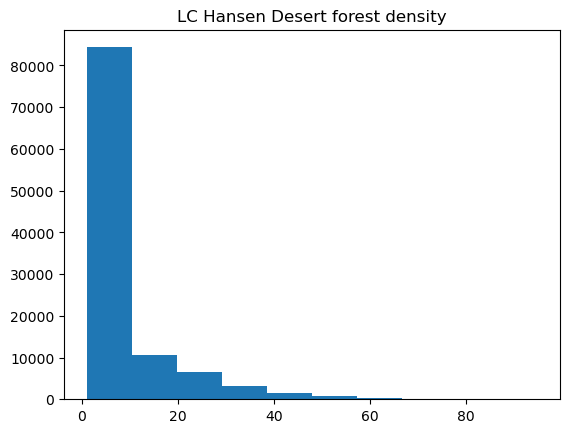

In [37]:
xarray.plot.hist(desertTree_densitycleaned)
pyplot.title("LC Hansen Desert forest density")

Text(0.5, 1.0, 'LC Hansen Flooded grassland density')

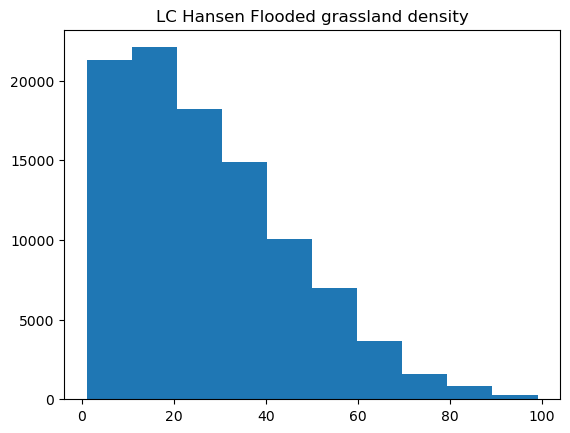

In [42]:
xarray.plot.hist(flooded_grassland_densitycleaned)
pyplot.title("LC Hansen Flooded grassland density")